# Looking at NAB before trusting any numbers

I wanted to see what the series and the labelled windows actually look like, and what each detector's score does on one series, before reading the big table.

In [1]:
import os, warnings
warnings.filterwarnings('ignore')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from windows import nab_names, load_nab
from evaluate import segments

names, windows = nab_names()
len(names)

34

## A few series with their windows

One from each folder. The shaded bits are the labelled anomaly windows, and the dashed line is where I split train and test.

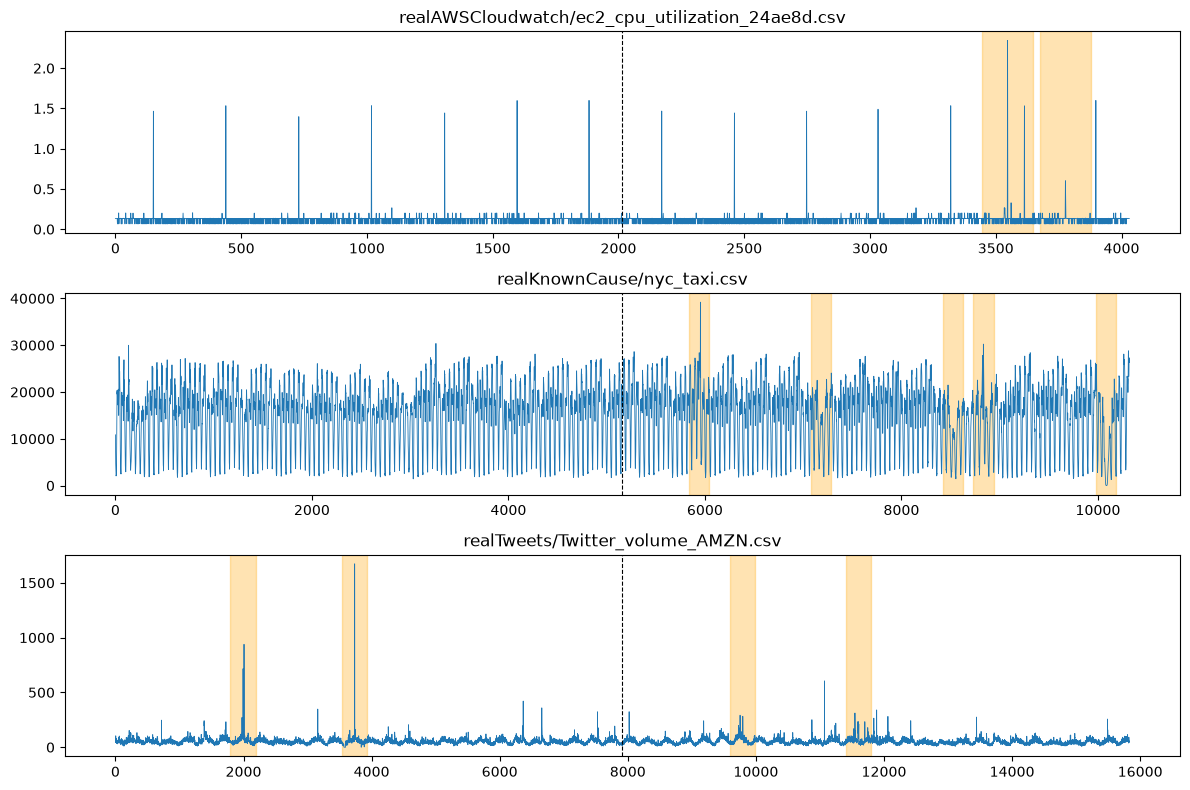

In [2]:
picks = ['realAWSCloudwatch/ec2_cpu_utilization_24ae8d.csv',
         'realKnownCause/nyc_taxi.csv',
         'realTweets/Twitter_volume_AMZN.csv']
fig, axes = plt.subplots(3, 1, figsize=(12, 8))
for ax, name in zip(axes, picks):
    x, y = load_nab(name, windows)
    ax.plot(x, lw=0.6)
    for s, e in segments(y):
        ax.axvspan(s, e - 1, color='orange', alpha=0.3)
    ax.axvline(len(x) // 2, color='k', ls='--', lw=0.8)
    ax.set_title(name)
fig.tight_layout()

The windows are wide. NAB sizes them so that all windows together cover about 10% of each file, which means one window can be hundreds or thousands of points long. That's the setting where point adjustment should hurt most: one lucky hit buys the whole window.

In [3]:
rows = []
for name in names:
    x, y = load_nab(name, windows)
    half = len(x) // 2
    segs = segments(y[half:])
    rows.append({'series': name.split('/')[1][:-4], 'n': len(x), 'train_anomaly_rate': y[:half].mean(),
                 'test_anomaly_rate': y[half:].mean(), 'test_windows': len(segs),
                 'mean_window_len': np.mean([e - s for s, e in segs]) if segs else 0})
stats = pd.DataFrame(rows)
stats.round(3)

,series,n,train_anomaly_rate,test_anomaly_rate,test_windows,mean_window_len
0,ec2_cpu_utilization_24ae8d,4032,0.000,0.199,2,201.000
1,ec2_cpu_utilization_53ea38,4032,0.100,0.100,1,201.000
2,ec2_cpu_utilization_5f5533,4032,0.100,0.100,1,201.000
3,ec2_cpu_utilization_77c1ca,4032,0.125,0.075,1,152.000
4,ec2_cpu_utilization_825cc2,4032,0.170,0.000,0,0.000
5,ec2_cpu_utilization_ac20cd,4032,0.000,0.200,1,403.000
6,ec2_cpu_utilization_c6585a,4032,0.000,0.000,0,0.000
7,ec2_cpu_utilization_fe7f93,4032,0.067,0.134,2,135.000
8,ec2_disk_write_bytes_1ef3de,4730,0.000,0.200,1,473.000
9,ec2_disk_write_bytes_c0d644,4032,0.067,0.134,2,135.000


Two things I don't love here. Some series have no window in the test half (those get dropped), and many have windows in the train half, so the training data for the LSTM and the forest isn't clean.

## Score traces on one series

machine_temperature_system_failure, test half only. These come from the seed 0 run saved by run.py.

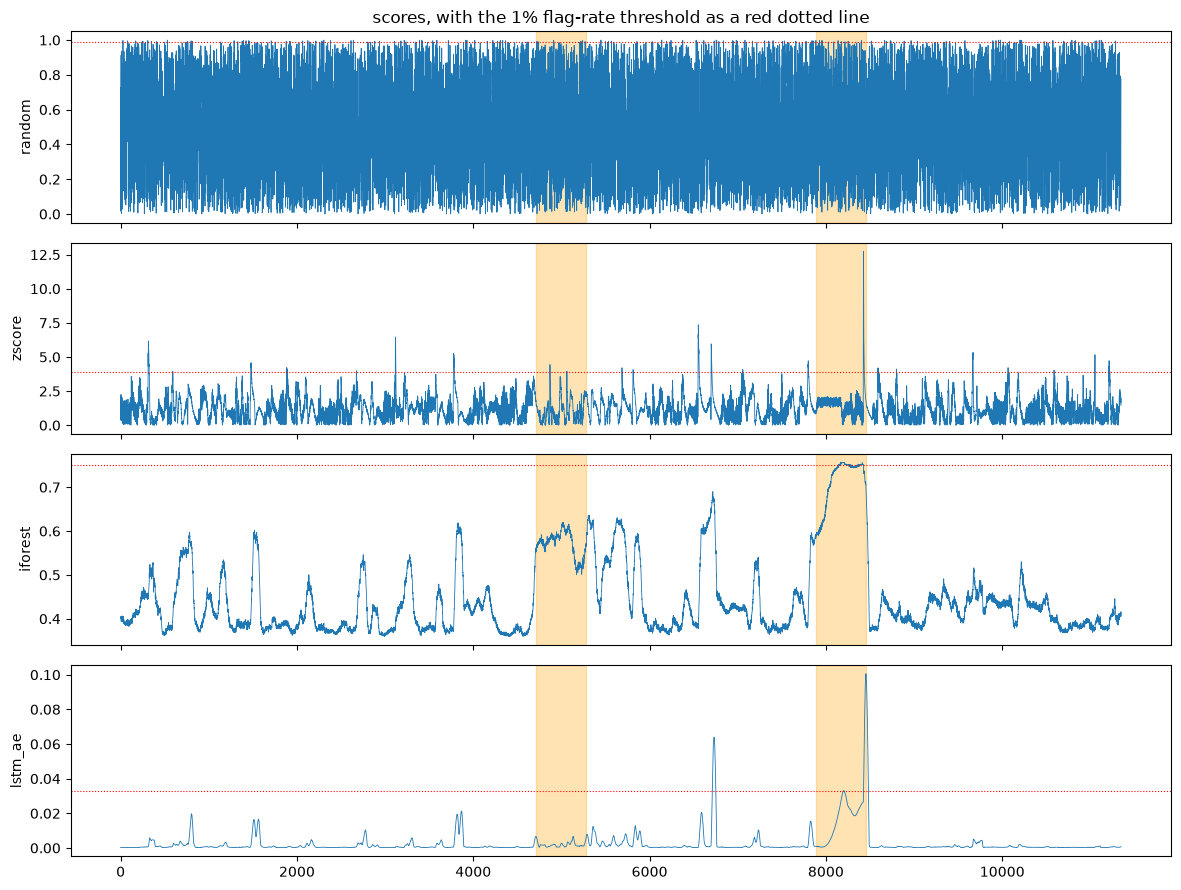

In [4]:
ex = 'realKnownCause/machine_temperature_system_failure.csv'
traces = np.load('results/traces.npz')
y = traces[ex + '|label']
dets = ['random', 'zscore', 'iforest', 'lstm_ae']
fig, axes = plt.subplots(len(dets), 1, figsize=(12, 9), sharex=True)
for ax, det in zip(axes, dets):
    s = traces[ex + '|' + det]
    ax.plot(s, lw=0.6)
    for a, b in segments(y):
        ax.axvspan(a, b - 1, color='orange', alpha=0.3)
    ax.axhline(np.quantile(s, 0.99), color='r', lw=0.8, ls=':')
    ax.set_ylabel(det)
axes[0].set_title('scores, with the 1% flag-rate threshold as a red dotted line')
fig.tight_layout()

## Per-series numbers for that example

In [5]:
df = pd.read_csv('results/summary.csv')
(df[df.series == ex].groupby('detector')[['f1', 'pa_f1', 'f1_at1', 'pa_f1_at1', 'auroc']]
   .mean().round(3))

,f1,pa_f1,f1_at1,pa_f1_at1,auroc
detector,,,,,
iforest,0.690,0.923,0.184,0.667,0.965
lstm_ae,0.406,0.805,0.052,0.636,0.843
random,0.183,0.978,0.016,0.956,0.506
zscore,0.204,0.957,0.021,0.957,0.548


## The final table

Median across series, IQR in brackets. Same file as results/aggregate.md.

In [6]:
display(Markdown(open('results/aggregate.md').read()))

### nab (30 series)

| detector | F1 | PA-F1 | F1 @1% | PA-F1 @1% | AUROC |
|---|---|---|---|---|---|
| random | 0.188 [0.158, 0.290] | 0.969 [0.953, 0.981] | 0.017 [0.013, 0.019] | 0.914 [0.640, 0.957] | 0.500 [0.495, 0.508] |
| zscore | 0.219 [0.181, 0.306] | 0.980 [0.958, 1.000] | 0.028 [0.016, 0.037] | 0.957 [0.918, 0.969] | 0.487 [0.462, 0.547] |
| iforest | 0.338 [0.199, 0.455] | 0.951 [0.781, 1.000] | 0.082 [0.019, 0.177] | 0.729 [0.548, 0.966] | 0.614 [0.513, 0.689] |
| lstm_ae | 0.376 [0.242, 0.449] | 0.958 [0.719, 1.000] | 0.097 [0.040, 0.149] | 0.891 [0.507, 0.998] | 0.654 [0.488, 0.699] |

Median across series, interquartile range in brackets. F1 and PA-F1 use the best of 200 thresholds per series; the @1% columns use the threshold that flags 1% of test points. Seeds are averaged within a series first.


## What I take from this

Point adjustment pushes every detector to about 0.95 or higher, and the random control lands in the same place. On this data PA-F1 can't tell a detector from a coin. Plain F1 is low for everything, but at least it orders the detectors in a way that matches what the score traces look like: the LSTM AE and the forest put their peaks near the failures, the z-score mostly reacts to ordinary dips. The z-score is barely better than random on plain F1 and ends up top of the table under PA, which says more about the metric than the detector.